## House Prices (Target Analysis)

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from house_prices_mlops.pipeline import load_stage
from house_prices_mlops.data_tracker import DataTracker

df_hp = load_stage("train")
tracker = DataTracker.load(df_hp)
target = "SalePrice"


2026-10-11 07:02:25.722 | INFO     | house_prices_mlops.config:<module>:11 - PROJ_ROOT path is: /home/jovyan/notebooks/house_prices_cookiecutter/house-prices-mlops


SalePrice is analyzed using training data only. No transformations are applied and no observations are removed.

### Basic Statistics

In [2]:

target_profile = tracker.profile.loc[
    tracker.profile['var'] == target,
    [
        'var',
        'variable_type',
        'missing_count',
        'missing_pct',
        'min',
        'max',
        'mean',
        'median',
        'std'
    ]
]

display(target_profile)


,var,variable_type,missing_count,missing_pct,min,max,mean,median,std
80,SalePrice,continuous,0,0.0,34900.0,745000.0,181441.541952,165000.0,77263.583862


### Skewness and Distribution

In [3]:
#Skewness and Distribution


# TARGET ANALYSIS - SKEWNESS & DISTRIBUTION


target_distribution = tracker.profile.loc[
    tracker.profile['var'] == target,
    [
        'var',
        'skewness',
        'kurtosis'
    ]
]

display(target_distribution)


,var,skewness,kurtosis
80,SalePrice,1.743129,5.475315


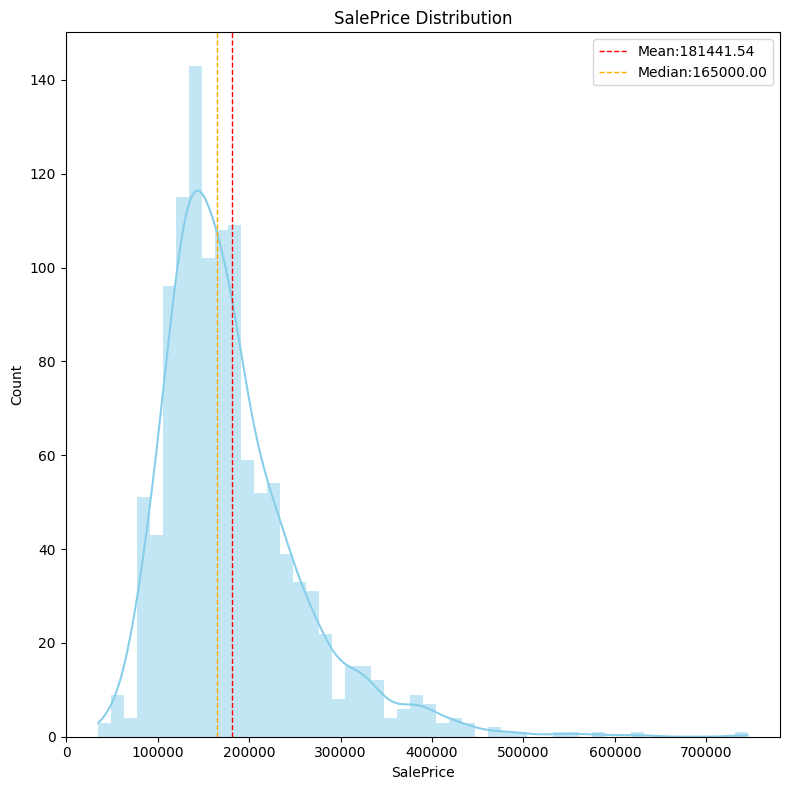

In [4]:
#Skewness and Distribution Plot

mean=df_hp['SalePrice'].mean()
median=df_hp['SalePrice'].median()

fig,ax=plt.subplots(figsize=(8,8))

sns.histplot(df_hp['SalePrice'],ax=ax,bins=50,kde=True,color='skyblue',linewidth=0)
ax.axvline(mean,color='red',linestyle='--',linewidth=1,label=f'Mean:{mean:.2f}')
ax.axvline(median,color='orange',linestyle='--',linewidth=1,label=f'Median:{median:.2f}')

ax.set_title('SalePrice Distribution')
ax.legend()
fig.tight_layout()
plt.show()


### Outliers (IQR)

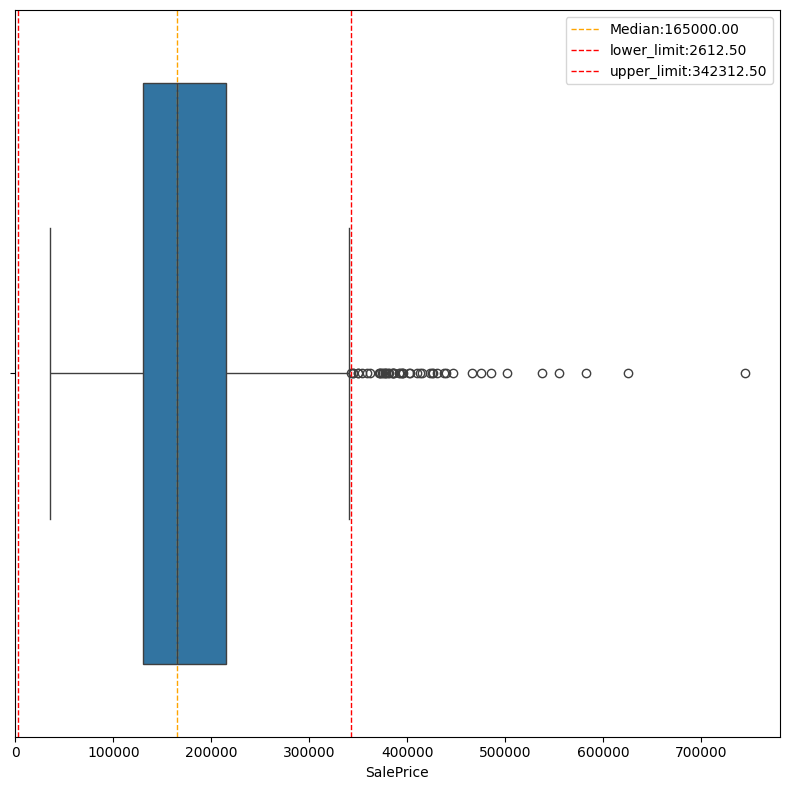

In [5]:
#Outliers

q1=df_hp['SalePrice'].quantile(.25)
q3=df_hp['SalePrice'].quantile(.75)

iqr=q3-q1

lower_limit=q1-(1.5*iqr)
upper_limit=q3+(1.5*iqr)

fig,ax=plt.subplots(figsize=(8,8))

sns.boxplot(data=df_hp,x='SalePrice',ax=ax)
ax.axvline(df_hp['SalePrice'].median(),color='orange',linestyle='--',linewidth=1,label=f'Median:{median:.2f}')
ax.axvline(lower_limit,color='red',linestyle='--',linewidth=1,label=f'lower_limit:{lower_limit:.2f}')
ax.axvline(upper_limit,color='red',linestyle='--',linewidth=1,label=f'upper_limit:{upper_limit:.2f}')
ax.legend()

fig.tight_layout()
plt.show()


### Findings

In [ ]:
tracker.add_finding(key='sale_price_skewness', 
    var='SalePrice',
    stage='DU - Target Analysis - Distribution',
    finding=(
        'SalePrice presenta una marcada asimetría positiva; '
        'se debe evaluar una transformación de su distribución en DP.'
    )
)

tracker.add_finding(key='sale_price_iqr_outliers', 
    var='SalePrice',
    stage='DU - Target Analysis - Outliers',
    finding=(
        f'Las observaciones de entrenamiento en la cola superior exceden el límite superior del IQR ({upper_limit:,.2f}); '
        'requieren evaluación y no deben eliminarse automáticamente.'
    )
)


### Save Findings

In [ ]:
tracker.save()